# Wave 4: Fig 3, Fig 4, Fig 5 and the final table

Contract: `audit/contracts/W4_figures_table.md` (decisions F1–F6, F5). Code: `src/w4_outputs.py`.
Nothing is recomputed: every number shown is read from M3, M2a or M2c outputs, and each builder asserts that
what it shows equals its source file.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import display

from src import w4_outputs as w4

pd.set_option("display.width", 200, "display.max_columns", 30)
PROC, FIG, RES = ROOT / "data/processed", ROOT / "figures", ROOT / "results"
RES.mkdir(exist_ok=True)


def save(fig, name):
    for ext in ("png", "pdf"):
        fig.savefig(FIG / f"{name}.{ext}", dpi=200, bbox_inches="tight")

## Fig 3: IFN signature score, control vs stimulated, per cell type (F1, F2)
Violins: per-cell scores of kept samples only (A1: DCs 6 donors, megakaryocytes 4). Dots: donor means from
`m3_sample_scores.csv`, joined ctrl→stim. `kept_cells` asserts the cell counts and means equal that file.

cells: 24562 in m3_cell_scores -> 24451 in kept samples (111 from donors dropped by A1); samples: 116


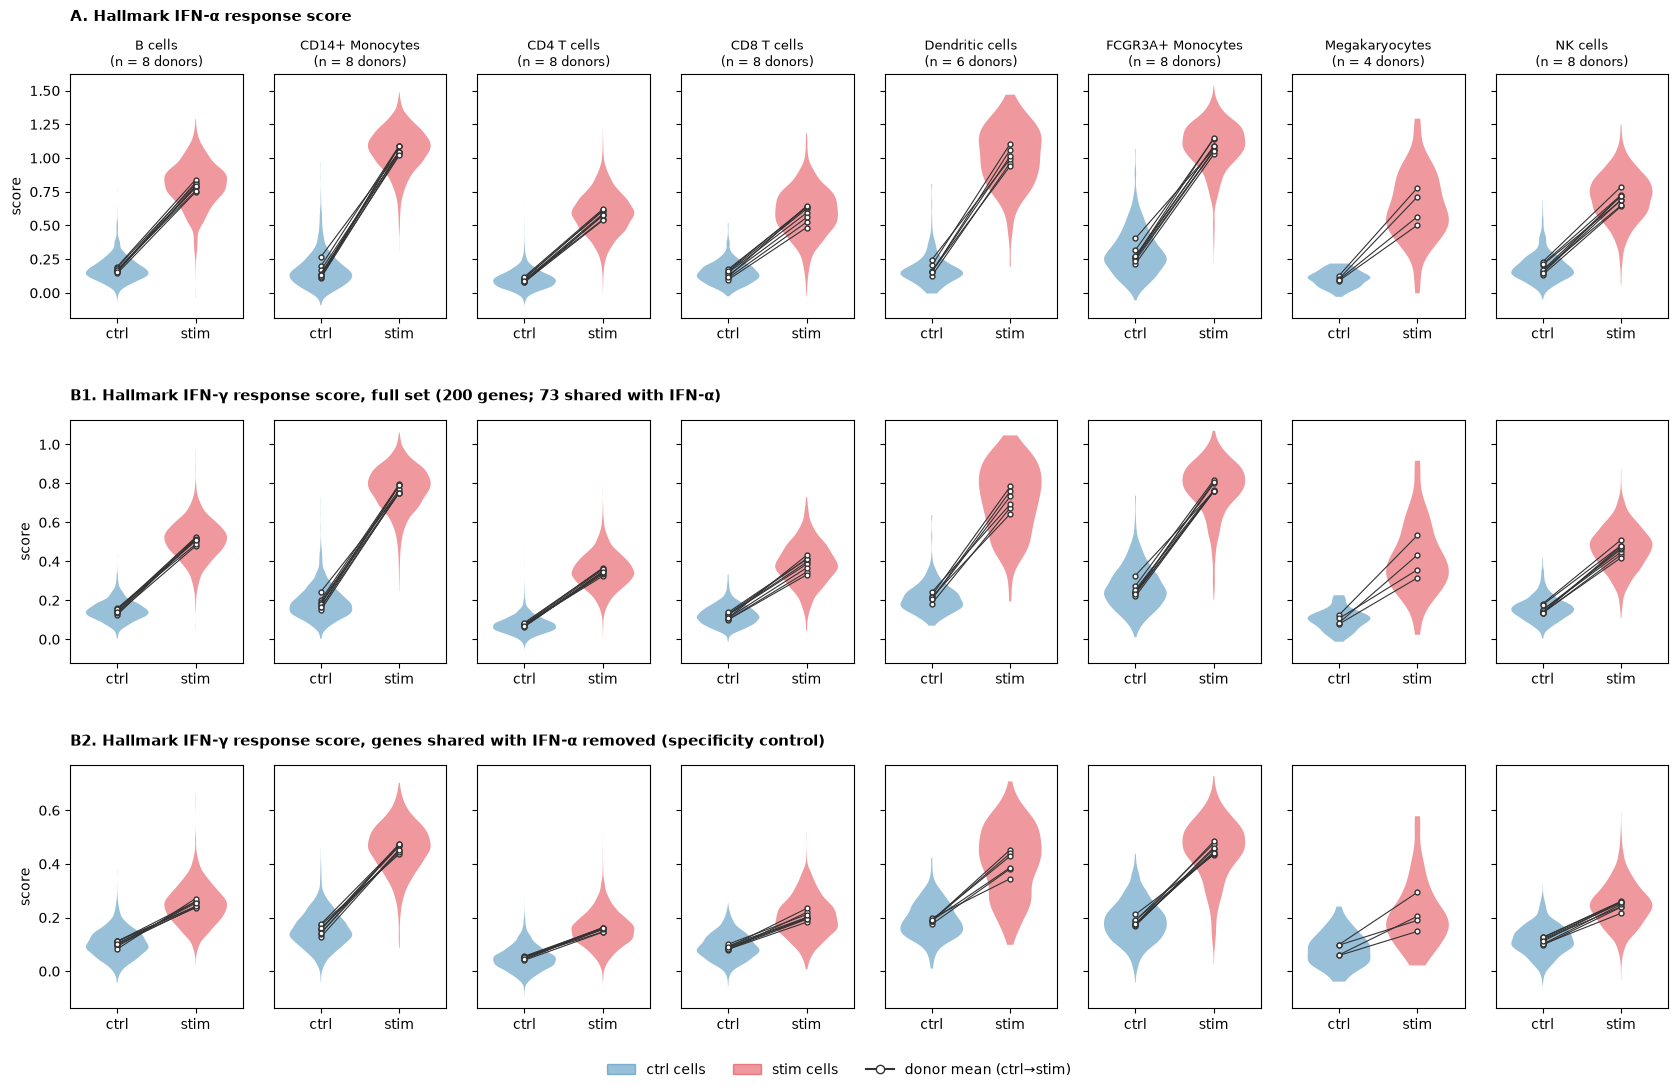

In [2]:
cell_scores = pd.read_csv(PROC / "m3_cell_scores.csv")
sample_scores = pd.read_csv(PROC / "m3_sample_scores.csv")
cells = w4.kept_cells(cell_scores, sample_scores)
print(f"cells: {len(cell_scores)} in m3_cell_scores -> {len(cells)} in kept samples "
      f"({len(cell_scores) - len(cells)} from donors dropped by A1); samples: {len(sample_scores)}")
assert len(cells) == sample_scores["n_cells"].sum()
fig3 = w4.plot_fig3(cells, sample_scores)
save(fig3, "fig3_ifn_signature")

## Fig 4: top shared and cell-type-specific genes (F3–F5)
Columns: average-linkage clustering of the up-regulated Jaccard matrix (1 − J). Rows: top 25 shared + shared\*
by mean |log2FC| over the 8 cell types; then per cell type (in column order) up to 5 specific genes tested in all
8 cell types, by |log2FC| (F3 revised). \* in a label = shared\* / specific\*.

Fig 4 column order: ['Megakaryocytes', 'CD14+ Monocytes', 'FCGR3A+ Monocytes', 'Dendritic cells', 'CD8 T cells', 'NK cells', 'B cells', 'CD4 T cells']
rows per group: {'shared': 25, 'Megakaryocytes': 2, 'CD14+ Monocytes': 5, 'FCGR3A+ Monocytes': 5, 'Dendritic cells': 5, 'CD8 T cells': 4, 'NK cells': 5, 'B cells': 5, 'CD4 T cells': 5}
cells: 488; untested (grey): 0; DE (dot): 228; every tested cell equals m2_calls log2FC


,gene,label,group,rank_value,display
0,CXCL10,shared*,shared,7.894301,CXCL10*
1,IFIT1,shared,shared,7.298297,IFIT1
2,CCL8,shared*,shared,7.153242,CCL8*
3,IFIT3,shared,shared,6.974067,IFIT3
4,RSAD2,shared,shared,6.947704,RSAD2
...,...,...,...,...,...
56,IDH2,specific*,CD4 T cells,1.521776,IDH2*
57,UBQLN2,specific*,CD4 T cells,1.504096,UBQLN2*
58,RGS1,specific*,CD4 T cells,1.278009,RGS1*
59,MKRN1,specific*,CD4 T cells,1.251693,MKRN1*


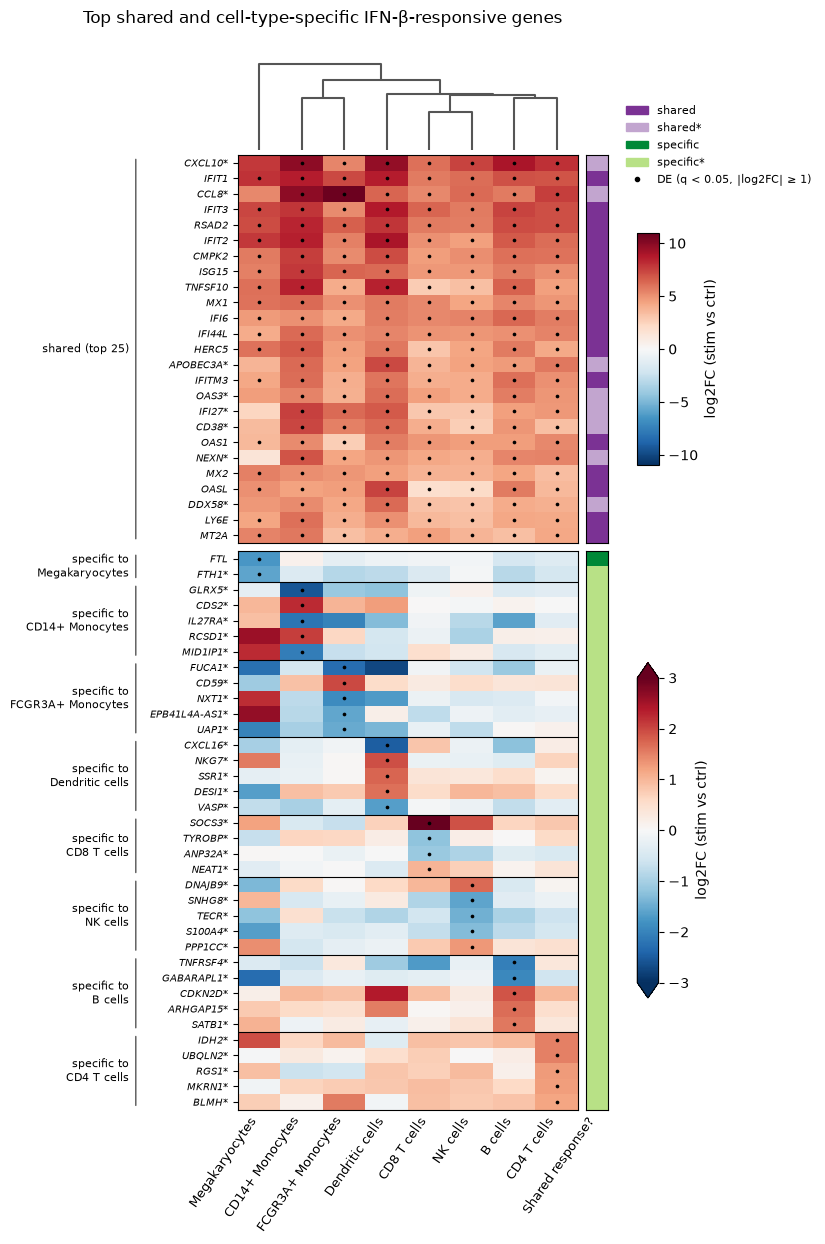

In [3]:
table = pd.read_csv(PROC / "m2_table.csv")
calls = pd.read_csv(PROC / "m2_calls.csv")
jac = pd.read_csv(PROC / "m2c_jaccard.csv", index_col=[0, 1])
col4, Z4 = w4.jaccard_order(jac)
rows4 = w4.fig4_rows(table, calls, col4)
lfc4, de4 = w4.fig4_matrix(rows4, calls, col4)
print("Fig 4 column order:", col4)
print("rows per group:", rows4.groupby("group", sort=False).size().to_dict())
print(f"cells: {lfc4.size}; untested (grey): {int(lfc4.isna().sum().sum())}; DE (dot): {int(de4.sum().sum())}; "
      "every tested cell equals m2_calls log2FC")
display(rows4)
fig4 = w4.plot_fig4(rows4, lfc4, de4, Z4)
save(fig4, "fig4_de_heatmap")

## Fig 5: response programs across cell types
Columns: average-linkage clustering on NES profiles (1 − Pearson r) over affected programs tested in all 8.
Rows: the 58 affected programs grouped by label; within a label by number of affected cell types, then mean NES.

Fig 5 column order: ['CD4 T cells', 'Megakaryocytes', 'B cells', 'CD8 T cells', 'NK cells', 'Dendritic cells', 'CD14+ Monocytes', 'FCGR3A+ Monocytes'] (clustered on 46 programs tested in all 8)
rows per label: {'shared': 5, 'partial': 36, 'specific': 16, 'mixed': 1}
cells: 464; n/t: 30; significant (dot): 200; every cell equals m2c_gsea NES; arrows equal m2c_programs


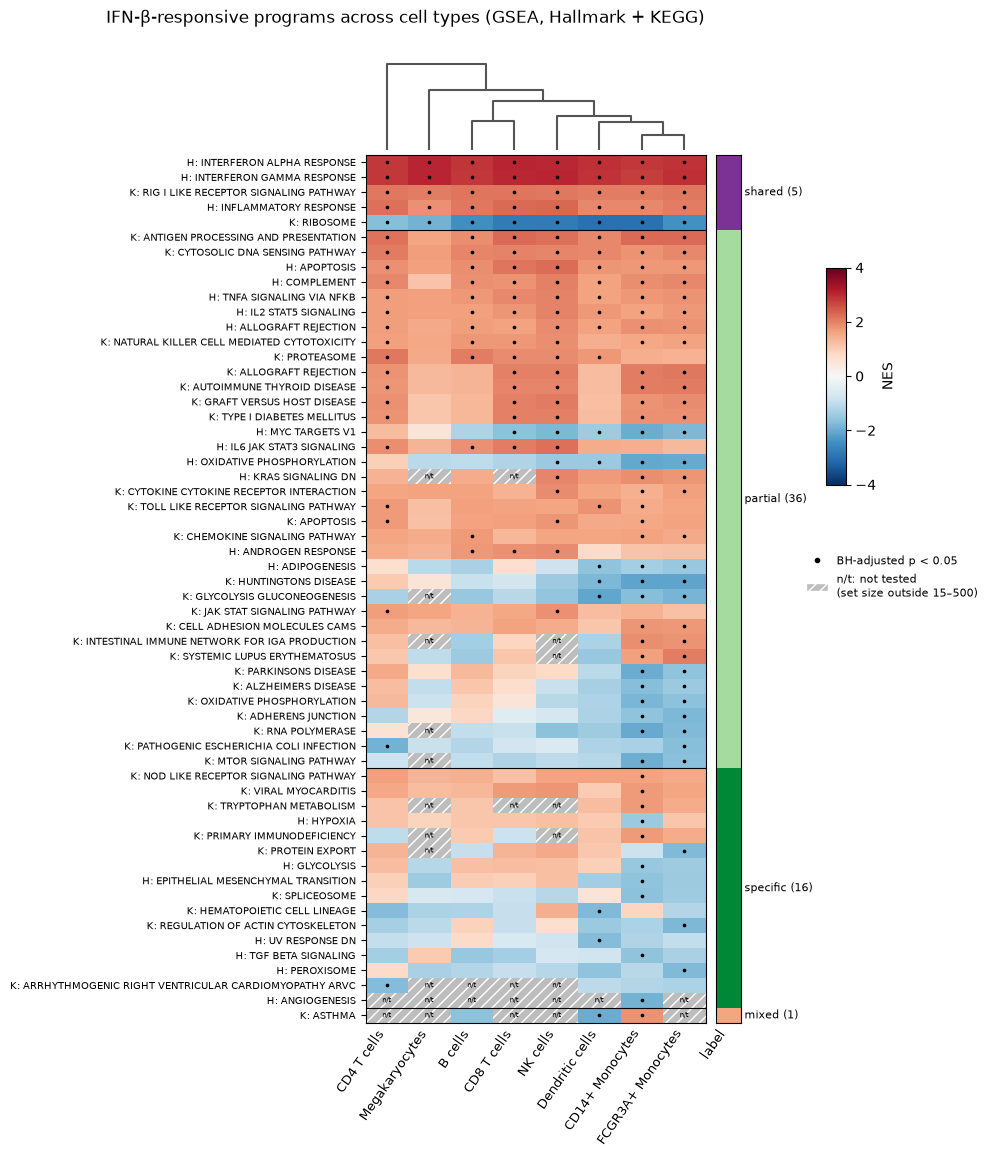

In [4]:
gsea = pd.read_csv(PROC / "m2c_gsea.csv")
programs = pd.read_csv(PROC / "m2c_programs.csv")
col5, Z5, n_complete = w4.nes_order(gsea, programs)
rows5, nes5, sig5 = w4.fig5_matrix(gsea, programs, col5)
print("Fig 5 column order:", col5, f"(clustered on {n_complete} programs tested in all 8)")
print("rows per label:", rows5["label"].value_counts().reindex(w4.PROGRAM_LABELS).to_dict())
print(f"cells: {nes5.size}; n/t: {int(nes5.isna().sum().sum())}; significant (dot): {int(sig5.sum().sum())}; "
      "every cell equals m2c_gsea NES; arrows equal m2c_programs")
fig5 = w4.plot_fig5(rows5, nes5, sig5, Z5)
save(fig5, "fig5_programs_heatmap")

## Final table (F6)
`final_table` asserts every arrow equals `m2_table.csv` and the `de` call in `m2_calls.csv`.

In [5]:
final = w4.final_table(table, calls)
# real-data check (kept here, not in the function, so final_table works on any input)
sp = final["Shared response?"] == "specific"
assert sp.sum() == 241 and (final.loc[sp, "expressed_in_n_cell_types"] == 1).sum() == 229, "expected 229 of 241 specific genes expressed in 1 cell type"
assert len(final) == len(table) == 2801
final.to_csv(RES / "final_table.csv", index=False)
print(final.shape)
print(final["Shared response?"].value_counts().reindex(w4.LABEL_ORDER).to_dict())
display(final.head(10))
display(final.tail(5))

(2801, 29)
{'shared': 21, 'shared*': 87, 'partial': 856, 'mixed': 11, 'specific': 241, 'specific*': 1585}


,gene,B cells,CD14+ Monocytes,CD4 T cells,CD8 T cells,FCGR3A+ Monocytes,NK cells,Dendritic cells,Megakaryocytes,Shared response?,n_cell_types,expressed_in_n_cell_types,megakaryocyte_lower_confidence,B cells log2FC,B cells q,CD14+ Monocytes log2FC,CD14+ Monocytes q,CD4 T cells log2FC,CD4 T cells q,CD8 T cells log2FC,CD8 T cells q,FCGR3A+ Monocytes log2FC,FCGR3A+ Monocytes q,NK cells log2FC,NK cells q,Dendritic cells log2FC,Dendritic cells q,Megakaryocytes log2FC,Megakaryocytes q
0,IFIT1,↑,↑,↑,↑,↑,↑,↑,↑,shared,8,8,True,7.034287,1.031273e-25,8.639879,1.037178e-45,6.918262,4.394109e-67,5.752630,3.958424e-53,7.294073,5.752637e-43,6.150496,2.814298e-76,8.653786,1.341678e-27,7.942960,2.407561e-09
1,IFIT3,↑,↑,↑,↑,↑,↑,↑,↑,shared,8,8,True,7.394300,7.581882e-36,7.884604,5.806117e-63,7.084746,4.832191e-54,6.383301,1.481793e-44,5.222549,1.556795e-79,5.749206,1.220631e-39,8.743655,5.941009e-33,7.330172,2.033862e-08
2,RSAD2,↑,↑,↑,↑,↑,↑,↑,↑,shared,8,8,True,7.215681,7.018590e-30,8.373712,4.207087e-37,7.091879,1.055091e-24,5.694074,1.503220e-26,6.590434,5.306819e-24,5.601832,5.524998e-33,7.868956,1.458353e-29,7.145062,5.419988e-07
3,IFIT2,↑,↑,↑,↑,↑,↑,↑,↑,shared,8,8,True,6.764432,2.280634e-32,8.584393,3.001872e-47,6.174246,2.215508e-48,4.990103,1.465716e-21,5.507647,2.554898e-72,4.515981,1.007853e-30,8.997573,1.689505e-23,7.791254,7.553810e-09
4,CMPK2,↑,↑,↑,↑,↑,↑,↑,↑,shared,8,8,True,6.048483,2.585946e-31,7.597825,9.676775e-30,6.005339,8.957751e-23,4.638510,9.582105e-20,5.166820,2.116935e-24,5.139555,6.825271e-20,7.157104,4.511563e-14,5.688815,1.309843e-02
5,ISG15,↑,↑,↑,↑,↑,↑,↑,↑,shared,8,8,True,5.589977,9.117282e-224,7.744847,2.526764e-62,5.079555,1.032012e-96,4.773276,4.508474e-131,6.422980,5.608690e-54,4.741496,2.024054e-200,6.245084,1.613890e-146,5.568644,7.767434e-19
6,TNFSF10,↑,↑,↑,↑,↑,↑,↑,↑,shared,8,8,True,6.485113,2.825768e-70,8.425722,6.711624e-63,4.488248,3.466906e-238,2.781659,1.857069e-28,4.088372,1.885215e-82,3.275529,9.942214e-63,8.507464,2.136980e-18,6.098589,2.289677e-06
7,MX1,↑,↑,↑,↑,↑,↑,↑,↑,shared,8,8,True,5.404377,2.320435e-24,6.260065,2.038551e-37,4.887106,1.734834e-89,5.266357,3.558465e-39,5.038923,9.361038e-53,4.370874,8.957423e-46,5.755867,5.652203e-44,5.961392,2.289677e-06
8,IFI6,↑,↑,↑,↑,↑,↑,↑,↑,shared,8,8,True,6.335199,1.748623e-33,4.987974,2.358916e-25,5.658978,7.997948e-131,5.282171,2.287718e-105,4.182121,8.386154e-48,5.465821,3.680606e-36,5.598388,7.034050e-59,4.683721,1.088806e-09
9,IFI44L,↑,↑,↑,↑,↑,↑,↑,↑,shared,8,8,True,4.987524,5.246222e-20,6.217754,4.202602e-19,5.438301,1.207720e-22,4.927799,2.128540e-31,4.998984,1.052181e-11,4.878073,9.803861e-21,5.404140,2.329900e-20,4.062119,3.151132e-03


,gene,B cells,CD14+ Monocytes,CD4 T cells,CD8 T cells,FCGR3A+ Monocytes,NK cells,Dendritic cells,Megakaryocytes,Shared response?,n_cell_types,expressed_in_n_cell_types,megakaryocyte_lower_confidence,B cells log2FC,B cells q,CD14+ Monocytes log2FC,CD14+ Monocytes q,CD4 T cells log2FC,CD4 T cells q,CD8 T cells log2FC,CD8 T cells q,FCGR3A+ Monocytes log2FC,FCGR3A+ Monocytes q,NK cells log2FC,NK cells q,Dendritic cells log2FC,Dendritic cells q,Megakaryocytes log2FC,Megakaryocytes q
2796,FARSA,–,↓,–,–,–,–,–,–,specific*,1,7,False,-0.090149,0.798444,-1.690559,5.854519e-05,0.014134,0.772601,-0.024317,0.925083,0.092931,0.597679,-0.204975,0.849489,-0.034410,0.921912,0.047952,NaN
2797,NDUFA10,–,↓,–,–,–,–,–,–,specific*,1,8,False,-0.150884,0.746125,-1.049320,1.051754e-04,-0.129559,0.591130,-0.091690,0.912839,-0.284599,0.430307,-0.411315,0.637350,-0.141844,0.909606,-0.093215,0.999856
2798,ARMC8,–,↑,–,–,–,–,–,–,specific*,1,7,False,-0.064637,0.810862,1.040626,2.919363e-03,0.079910,0.720212,0.114932,0.917528,0.109818,0.591277,0.214944,0.851766,0.311327,0.898676,0.649493,NaN
2799,BIRC2,–,↑,–,–,–,–,–,–,specific*,1,8,False,-0.195448,0.768712,1.057306,4.837723e-05,-0.078778,0.665697,-0.176891,0.902920,-0.032904,0.615776,0.065363,0.863891,0.037223,0.921912,-0.382327,0.999856
2800,SRI,–,↑,–,–,–,–,–,–,specific*,1,8,False,0.193560,0.605951,1.042295,8.711391e-13,-0.025333,0.744863,0.091476,0.912839,0.052286,0.571876,0.101574,0.840261,0.030750,0.917973,-0.321300,0.999856
